# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the RSSCN7 dataset.

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import RSSCN7Dataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/RSSCN7", 
    "csv_file": "./data/RSSCN7/rsscn7_train.csv"
    }
dataset = RSSCN7Dataset(dataset_config)

## Show images from the dataset

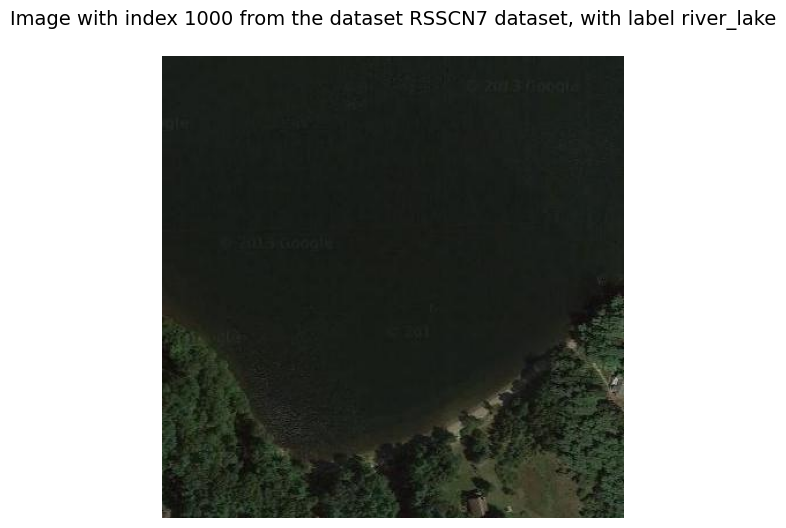

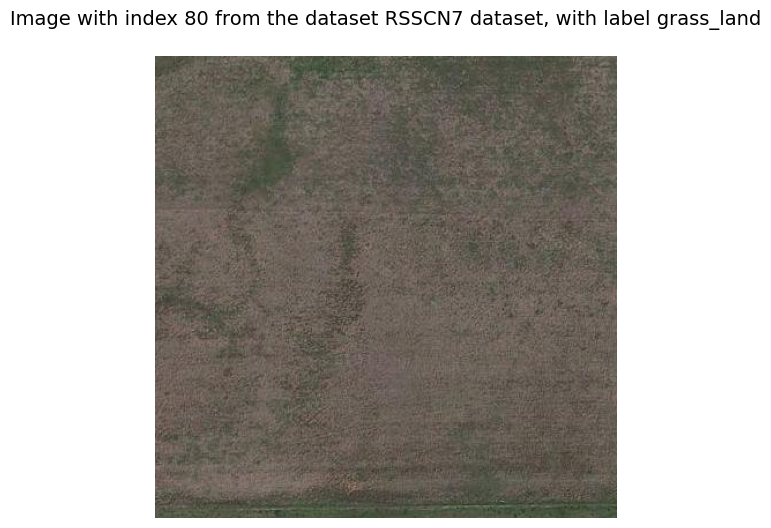

In [10]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

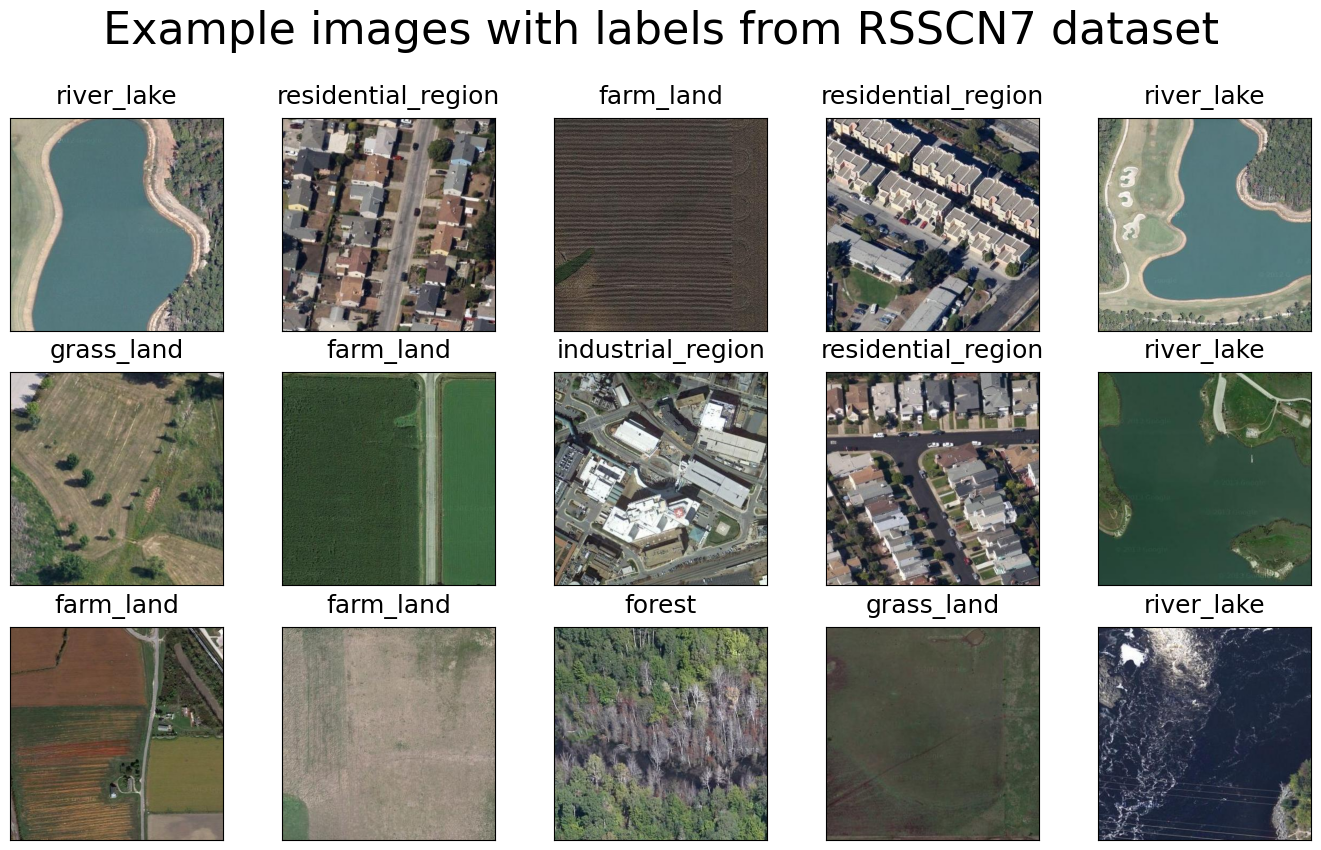

In [11]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [12]:
dataset.show_samples()

,File name,Label
0,farm_land/539.jpg,farm_land
1,farm_land/524.jpg,farm_land
2,grass_land/14.jpg,grass_land
3,grass_land/257.jpg,grass_land
4,river_lake/1386.jpg,river_lake
5,residential_region/2171.jpg,residential_region
6,river_lake/1399.jpg,river_lake
7,farm_land/732.jpg,farm_land
8,parking_lot/2667.jpg,parking_lot
9,grass_land/335.jpg,grass_land


In [13]:
dataset.data_distribution_table()

,Label,Count
0,farm_land,240
1,forest,240
2,grass_land,240
3,industrial_region,240
4,parking_lot,240
5,residential_region,240
6,river_lake,240


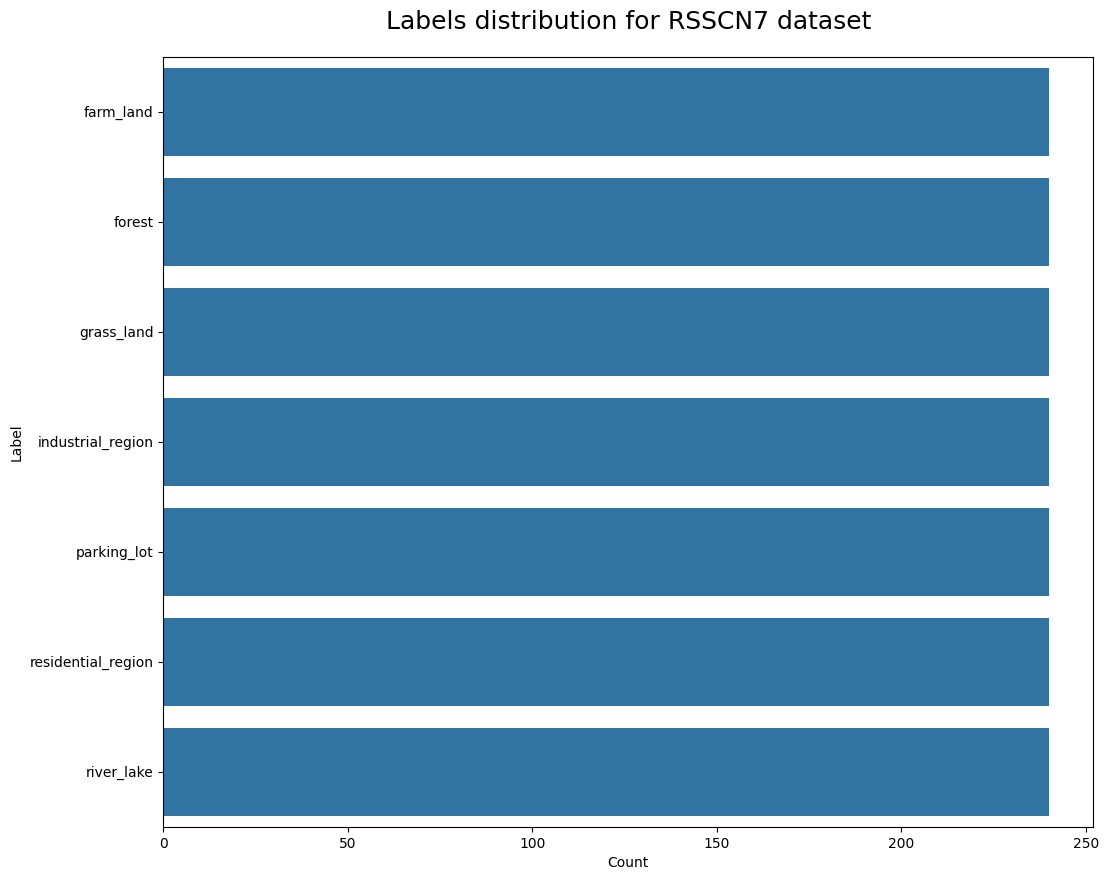

In [14]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/RSSCN7", 
    "csv_file": "./data/RSSCN7/rsscn7_train.csv"
}

train_dataset = RSSCN7Dataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/RSSCN7", 
    "csv_file": "./data/RSSCN7/rsscn7_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = RSSCN7Dataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(1680, 560)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/RSSCN7"
model_config = {
    "num_classes": 7,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [18]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 10:59:11,609 INFO Starting training.
training: 100%|██████████| 105/105 [00:09<00:00, 11.66it/s]
2026-08-24 10:59:20,976 INFO epoch: 1, time: 9, loss:  1.38608
testing on train set: 100%|██████████| 105/105 [00:05<00:00, 19.92it/s]
2026-08-24 10:59:27,252 INFO Accuracy:0.8970238095238096, Precision Micro:0.8970238095238096, Precision Macro:0.8991566022671895, Precision Weighted:0.8991566022671894, Precision per Class:[0.92975207 0.95081967 0.9017094  0.75862069 0.90909091 0.88306452
 0.96103896], Recall Micro:0.8970238095238096, Recall Macro:0.8970238095238096, Recall Weighted:0.8970238095238094, Recall per Class:[0.9375     0.96666667 0.87916667 0.825      0.83333333 0.9125
 0.925     ], F1_score Micro:0.897023809523809, F1_score Macro:0.8975405035738, F1_score Weighted:0.8975405035737999, F1_score per Class:[0.93360996 0.95867769 0.89029536 0.79041916 0.86956522 0.89754098
 0.94267516]
testing on validation set: 100%|██████████| 140/140 [00:04<00:00, 28.00it/s]
2026-08-24 

0.0865397251033712

## Predictions

2026-08-24 11:01:35,119 INFO Loading checkpoint /home/dragik/data/experiments/RSSCN7/checkpoint.pth.tar
2026-08-24 11:01:35,744 INFO Loaded checkpoint /home/dragik/data/experiments/RSSCN7/checkpoint.pth.tar at epoch 11


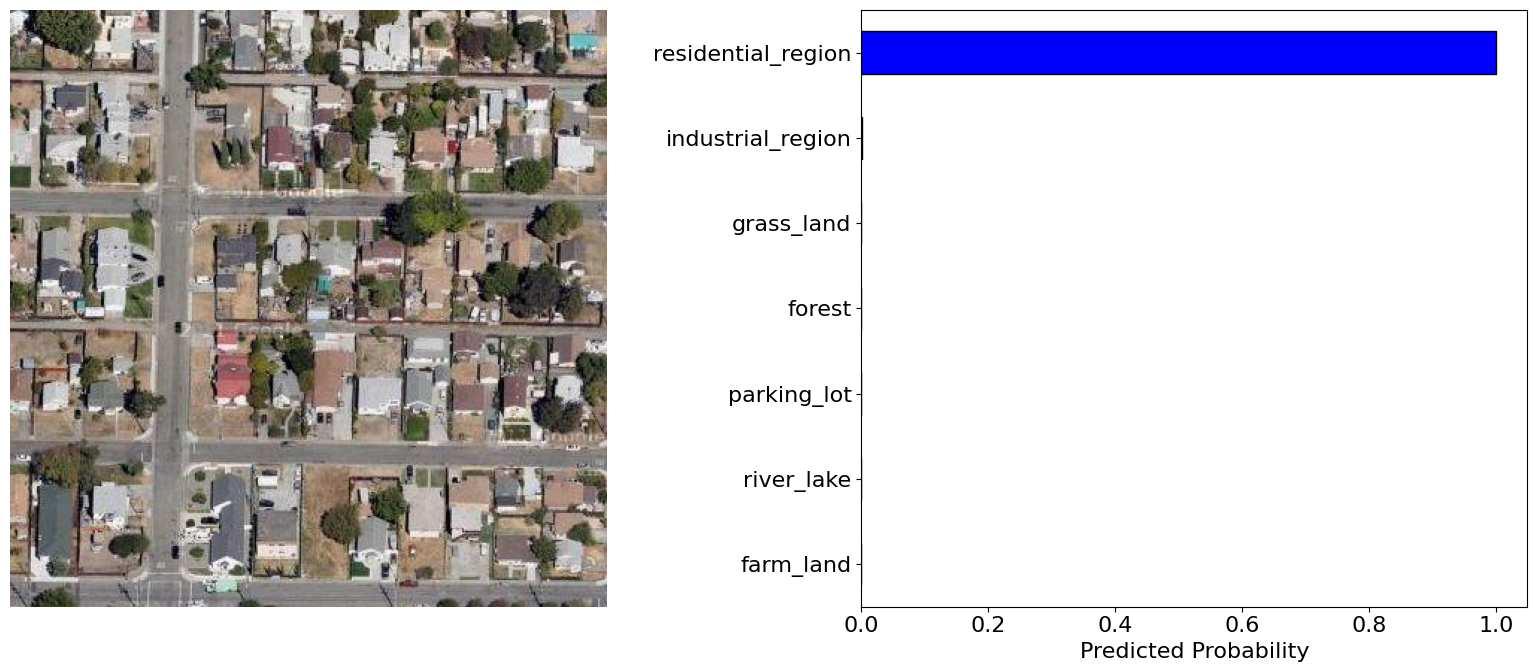

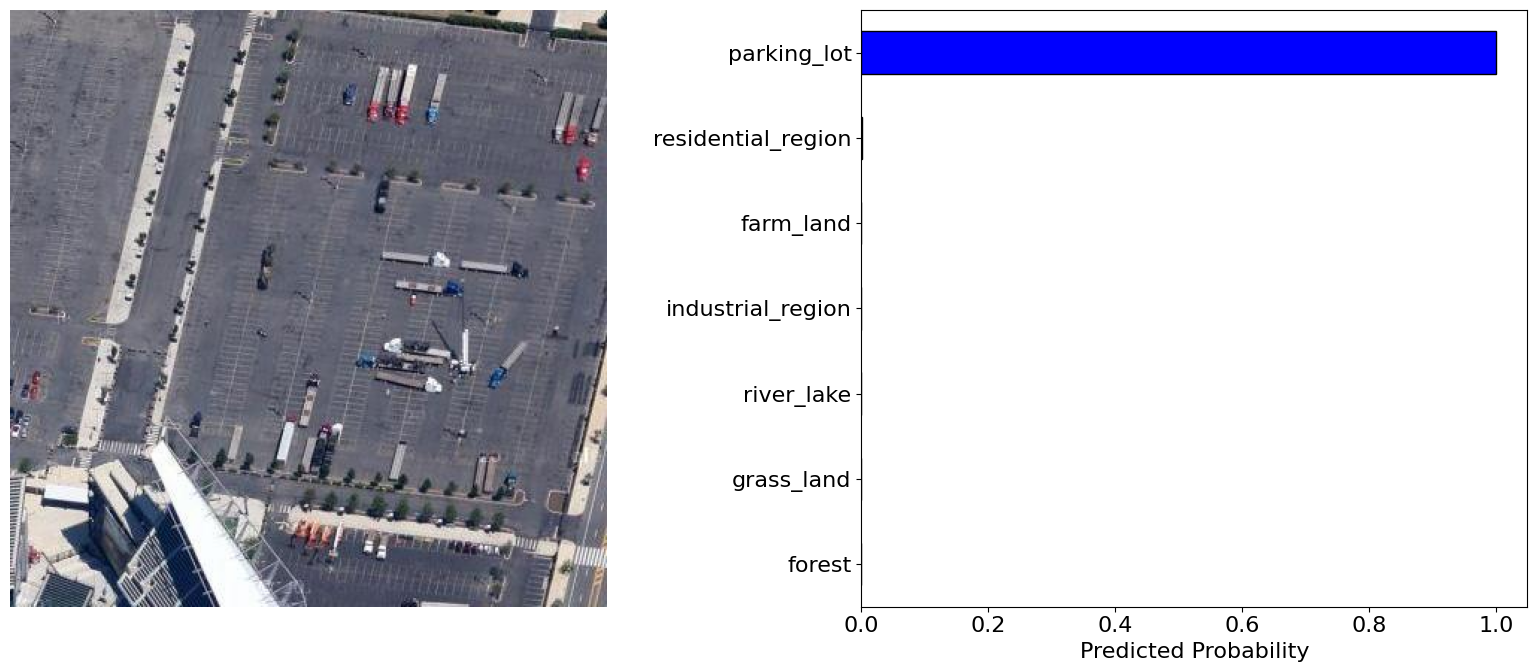

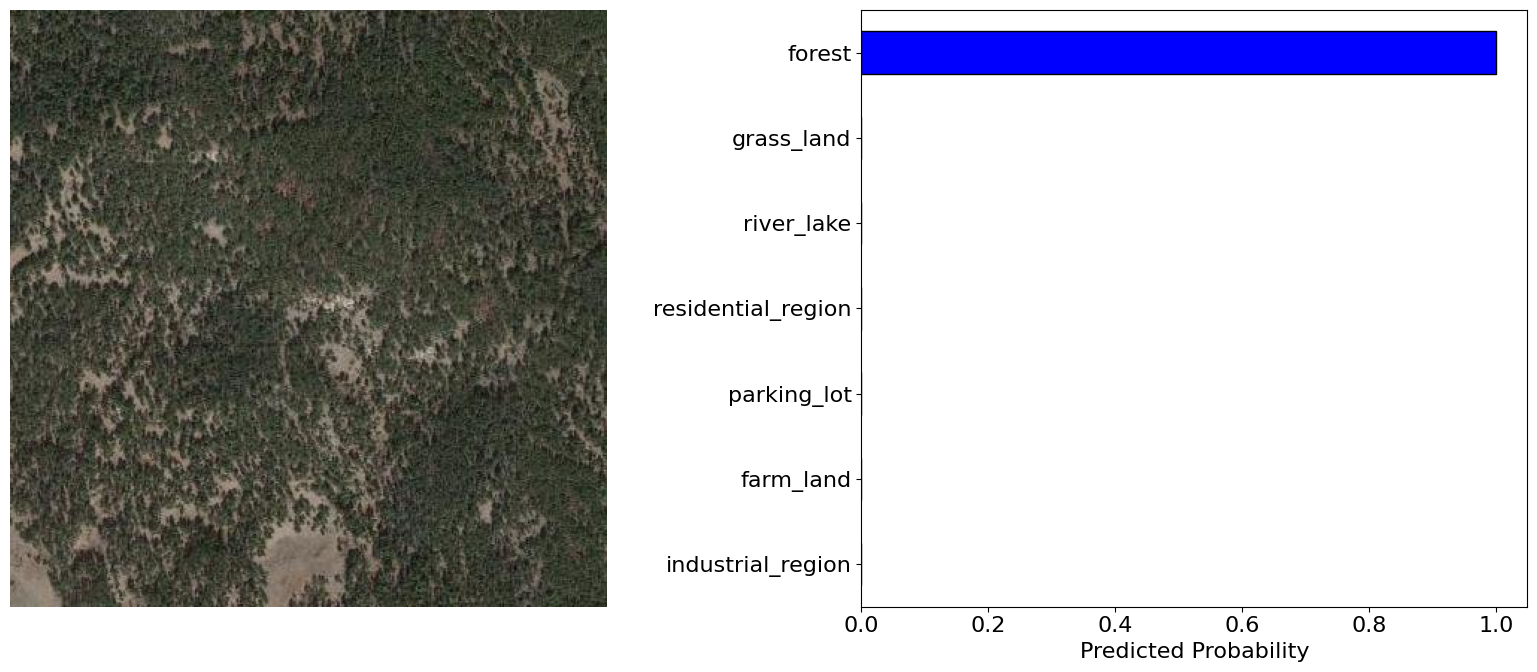

In [ ]:
model_path = "./data/experiments/RSSCN7/checkpoint.pth.tar"
labels = [
    "farm_land",
    "forest",
    "grass_land",
    "industrial_region",
    "parking_lot",
    "residential_region",
    "river_lake",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader("./data/RSSCN7/residential_region/2111.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/RSSCN7/parking_lot/2589.jpg")
fig = model.predict_image(image, labels, transform)

image = image_loader("./data/RSSCN7/forest/2000.jpg")
fig = model.predict_image(image, labels, transform)